# Detección de URLs de *phishing* — Reducción de dimensión
### Proyecto — Introducción al Machine Learning (Modelos II)

Este notebook corresponde a la sección **Reducción de dimensión** del informe. Responde si se puede mantener el
desempeño con menos variables, en el escenario **Solo URL** (19 variables) y con los dos mejores modelos del notebook
`02_modelos.ipynb`:

1. **Análisis individual:** índice de Fisher, AUC univariado, información mutua y correlación entre variables.
2. **Selección de variables:** comprobación con los modelos de qué variables se pueden eliminar.
3. **PCA:** extracción lineal de componentes, con nueva búsqueda de hiperparámetros en cada dimensión.
4. **UMAP:** extracción no lineal, con nueva búsqueda de hiperparámetros en cada dimensión.

Todo usa la misma partición del notebook 2. Cada transformación se ajusta solo con los datos de entrenamiento de cada
pliegue, para que la validación no vea información de sí misma.

### Ejecución en Google Colab

Esta celda solo actúa en Colab: conecta Google Drive, instala las dependencias y trabaja en la carpeta
`proyecto-modelos2-phishing` de tu Drive, que ya debe tener `data/` y `results/`. Cada resultado se guarda al
terminar; si la sesión se desconecta, basta con volver a ejecutar todo.

In [ ]:
import os
import subprocess
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA = '/content/drive/MyDrive/proyecto-modelos2-phishing'
    os.makedirs(CARPETA, exist_ok=True)
    os.chdir(CARPETA)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn==1.9.1', 'umap-learn==0.5.12', 'ucimlrepo'],
                   check=True)
    print('Trabajando en:', os.getcwd())
    print('Archivos:', sorted(os.listdir('.')))

Mounted at /content/drive
Trabajando en: /content/drive/MyDrive/proyecto-modelos2-phishing
Archivos: ['cache_umap', 'data', 'figures', 'results']


## 5.1 Preparación
### Librerías y parámetros

In [ ]:
import hashlib
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef, recall_score, roc_auc_score
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='umap')

RANDOM_STATE = 42
RECALCULAR = False         # False: reutiliza lo guardado y calcula solo lo que falte
MUESTRAS_SUBCONJUNTO = 30_000
MUESTRAS_UMAP = 20_000     # UMAP aprende la proyección con esta muestra y la aplica a las demás
N_PLIEGUES = 5
UMBRALES_PCA = [.80, .95, .99]
DIMENSIONES_UMAP = [2, 5, 10]
PROCESOS = min(2, os.cpu_count())

RESULTADOS = Path('results')
FIGURAS = Path('figures')
CACHE = Path('cache_umap')
for carpeta in (RESULTADOS, FIGURAS, CACHE):
    carpeta.mkdir(exist_ok=True)
plt.rcParams['figure.dpi'] = 110

### Datos y partición

Se repite el preprocesamiento del notebook 2 y se comprueba que la partición de prueba sea exactamente la misma.

In [ ]:
RUTA_CSV = Path('data/PhiUSIIL_Phishing_URL_Dataset.csv')
if RUTA_CSV.exists():
    df = pd.read_csv(RUTA_CSV, encoding='utf-8', encoding_errors='replace',
                     usecols=lambda c: c not in ('FILENAME', 'TLD', 'Title'))
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=967)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)

df = df.drop_duplicates(subset='URL').reset_index(drop=True)

HTML = ['LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon',
        'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
        'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank',
        'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef',
        'NoOfExternalRef']
EXCLUIDAS = ['URLSimilarityIndex', 'IsHTTPS', 'TLDLegitimateProb']
NUMERICAS = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'label']
SOLO_URL = [c for c in NUMERICAS if c not in HTML + EXCLUIDAS]

y = (df['label'].to_numpy() == 0).astype(int)   # 1 = phishing
grupos = df['Domain'].to_numpy()
X = df[SOLO_URL].astype(np.float32)
del df

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(sgkf.split(X, y, grupos))

HUELLA_PRUEBA = '7f6be261f8cc6a84455909788d24e6cd'
huella = hashlib.md5(np.sort(idx_test).astype(np.int64).tobytes()).hexdigest()
if huella != HUELLA_PRUEBA:
    raise RuntimeError('La partición cambió: no mezcles estos resultados con los guardados en results/.')
print('Partición verificada')

n_partes = max(2, round(len(idx_train) / MUESTRAS_SUBCONJUNTO))
sub = StratifiedGroupKFold(n_splits=n_partes, shuffle=True, random_state=RANDOM_STATE)
_, pos_sub = next(sub.split(X.iloc[idx_train], y[idx_train], grupos[idx_train]))
idx_sub = idx_train[pos_sub]

cv = StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=RANDOM_STATE)
print(f'Variables: {len(SOLO_URL)} | Entrenamiento: {len(idx_train):,} | Prueba: {len(idx_test):,} | '
      f'Subconjunto: {len(idx_sub):,}')

Partición verificada
Variables: 19 | Entrenamiento: 188,296 | Prueba: 47,074 | Subconjunto: 31,383


### Modelos

`MEJORES_2` viene del notebook 2. Las mallas son las de ese notebook, con dos cambios en SVM para acotar el tiempo: se
omiten el *kernel* lineal y `C=0.1`, que quedaron muy por debajo del resto en el notebook 2.

In [ ]:
MEJORES_2 = json.loads((RESULTADOS / 'dos_mejores.json').read_text(encoding='utf-8'))
if sorted(MEJORES_2) != ['MLP', 'SVM']:
    raise RuntimeError(f'Este notebook está preparado para MLP y SVM, y el notebook 2 eligió {MEJORES_2}.')


def crear(nombre, parametros):
    if nombre == 'MLP':
        return MLPClassifier(batch_size=512, max_iter=100, early_stopping=True, n_iter_no_change=5,
                             random_state=RANDOM_STATE, **parametros)
    return SVC(kernel='rbf', random_state=RANDOM_STATE, **parametros)


def base(nombre):
    resumen = json.loads((RESULTADOS / f'mejor_{nombre}.json').read_text(encoding='utf-8'))
    parametros = {k.replace('modelo__', ''): (tuple(v) if isinstance(v, list) else v)
                  for k, v in resumen['mejores'].items() if k != 'modelo__kernel'}
    return resumen, parametros


MODELOS = {
    'MLP': {'indices': idx_train,
            'malla': {'hidden_layer_sizes': [(32,), (64, 32), (128, 64), (128, 64, 32)], 'alpha': [0.0001, 0.01]}},
    'SVM': {'indices': idx_sub,
            'malla': {'C': [1, 10, 100], 'gamma': [0.01, 0.1, 1, 'scale']}},
}
BASE = {nombre: base(nombre) for nombre in MODELOS}


def escalador():
    return Pipeline([('log', FunctionTransformer(np.log1p)), ('escala', StandardScaler())])


def pliegues(nombre):
    idx = MODELOS[nombre]['indices']
    for ajuste, evaluacion in cv.split(X.iloc[idx], y[idx], grupos[idx]):
        yield idx[ajuste], idx[evaluacion]


def metricas(modelo, Z, y_real):
    pred = modelo.predict(Z)
    puntaje = modelo.decision_function(Z) if hasattr(modelo, 'decision_function') else modelo.predict_proba(Z)[:, 1]
    return {'mcc': matthews_corrcoef(y_real, pred), 'exactitud': accuracy_score(y_real, pred),
            'f1': f1_score(y_real, pred), 'auc': roc_auc_score(y_real, puntaje),
            'fpr': 1 - recall_score(y_real, pred, pos_label=0),
            'fp': int(((pred == 1) & (y_real == 0)).sum()), 'fn': int(((pred == 0) & (y_real == 1)).sum())}


def ajustar(nombre, parametros, Z_a, y_a, Z_e, y_e):
    modelo = crear(nombre, parametros).fit(Z_a, y_a)
    return {'entrenamiento': metricas(modelo, Z_a, y_a), 'evaluacion': metricas(modelo, Z_e, y_e)}


def promedio(resultados, parte, metrica='mcc'):
    valores = [r[parte][metrica] for r in resultados]
    return float(np.mean(valores)), float(np.std(valores))


def intervalo_prueba(m, repeticiones=10_000):
    fp, fn = m['fp'], m['fn']
    positivos, negativos = int(y[idx_test].sum()), int((y[idx_test] == 0).sum())
    conteos = np.array([positivos - fn, fp, fn, negativos - fp], dtype=float)
    azar = np.random.default_rng(RANDOM_STATE)
    tp, fp_m, fn_m, tn = azar.multinomial(len(idx_test), conteos / conteos.sum(), size=repeticiones).astype(float).T
    denominador = np.sqrt((tp + fp_m) * (tp + fn_m) * (tn + fp_m) * (tn + fn_m))
    return float(2 * ((tp * tn - fp_m * fn_m) / np.where(denominador == 0, 1, denominador)).std())

## 5.2 Análisis individual de variables

Se calcula solo con el conjunto de entrenamiento:

- **Índice de Fisher:** distancia entre las medias de cada clase respecto a sus varianzas.
- **AUC univariado:** qué tan bien ordena la variable las clases por sí sola; 0,5 equivale al azar.
- **Información mutua:** capta también relaciones no monótonas, que el AUC no ve.
- **Correlación de Pearson entre variables:** detecta información repetida.

Pares con correlación absoluta >= 0,85: [('URLLength', 'NoOfLettersInURL', np.float64(0.9737863708279498))]
                            Fisher     AUC  Inf. mutua
Variable                                              
NoOfOtherSpecialCharsInURL  0.3650  0.8233      0.2357
SpacialCharRatioInURL       0.7626  0.8099      0.2113
URLCharProb                 0.5316  0.7663      0.1295
CharContinuationRate        0.5514  0.7488      0.1612
NoOfLettersInURL            0.1428  0.7406      0.1501
URLLength                   0.1280  0.7307      0.1634
NoOfDegitsInURL             0.1010  0.7266      0.1696
DegitRatioInURL             0.3990  0.7247      0.1650
LetterRatioInURL            0.2985  0.7134      0.3784
DomainLength                0.1683  0.6285      0.0847
NoOfQMarkInURL              0.0552  0.5305      0.0239
TLDLength                   0.0145  0.5289      0.0140
NoOfEqualsInURL             0.0194  0.5267      0.0203
NoOfSubDomain               0.0004  0.5102      0.0673
NoOfAmpersan

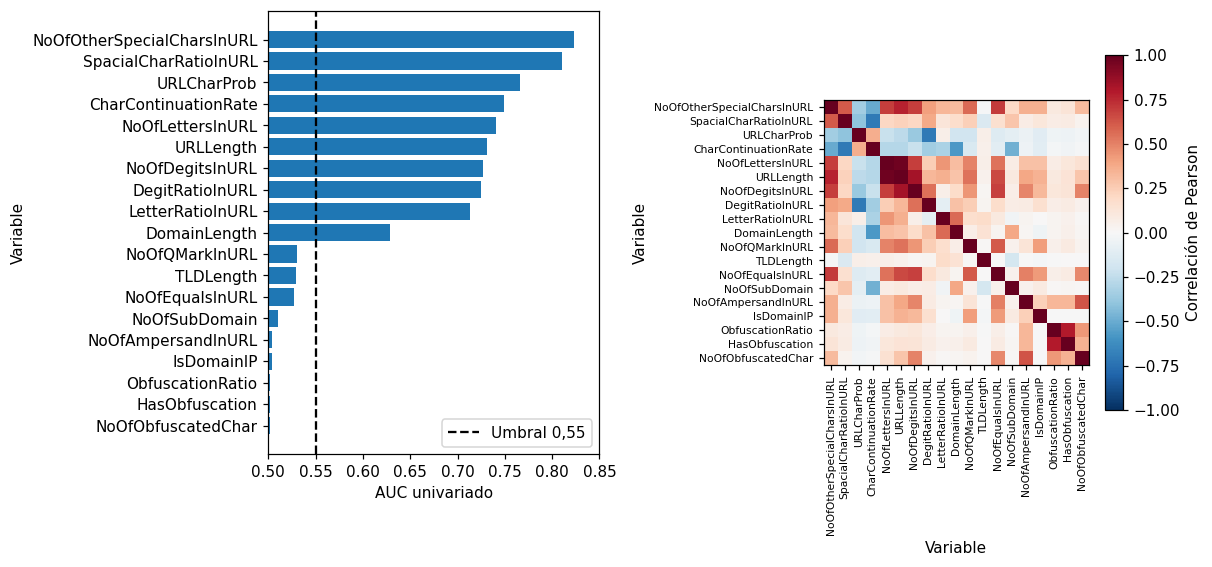

In [ ]:
X_ent, y_ent = X.iloc[idx_train], y[idx_train]
filas = []
for c in SOLO_URL:
    a, b = X_ent.loc[y_ent == 1, c], X_ent.loc[y_ent == 0, c]
    auc = roc_auc_score(y_ent, X_ent[c])
    filas.append({'Variable': c, 'Fisher': (a.mean() - b.mean()) ** 2 / (a.var() + b.var()), 'AUC': max(auc, 1 - auc)})
variables = pd.DataFrame(filas).set_index('Variable')
muestra = np.random.default_rng(RANDOM_STATE).choice(len(X_ent), min(40_000, len(X_ent)), replace=False)
variables['Inf. mutua'] = mutual_info_classif(X_ent.iloc[muestra], y_ent[muestra], random_state=RANDOM_STATE)
variables = variables.sort_values('AUC', ascending=False)
variables.to_csv(RESULTADOS / 'variables.csv')

correlacion = X_ent.corr()
pares = [(a, b, correlacion.loc[a, b]) for i, a in enumerate(SOLO_URL) for b in SOLO_URL[i + 1:]
         if abs(correlacion.loc[a, b]) >= .85]
print('Pares con correlación absoluta >= 0,85:', pares)
print(variables.round(4).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(11, 5.5))
ejes[0].barh(variables.index[::-1], variables['AUC'][::-1])
ejes[0].axvline(.55, color='k', ls='--', label='Umbral 0,55')
ejes[0].set_xlim(.5, .85)
ejes[0].set_xlabel('AUC univariado')
ejes[0].set_ylabel('Variable')
ejes[0].legend(loc='lower right')
mapa = ejes[1].imshow(correlacion.loc[variables.index, variables.index], cmap='RdBu_r', vmin=-1, vmax=1)
ejes[1].set_xticks(range(len(variables)), variables.index, rotation=90, fontsize=7)
ejes[1].set_yticks(range(len(variables)), variables.index, fontsize=7)
ejes[1].set_xlabel('Variable')
ejes[1].set_ylabel('Variable')
fig.colorbar(mapa, ax=ejes[1], label='Correlación de Pearson', shrink=.8)
plt.tight_layout()
plt.savefig(FIGURAS / 'analisis_variables.png', dpi=200)
plt.show()

### Selección de variables

Una variable débil sola puede servir combinada, así que los índices solo proponen candidatas. Los umbrales se fijan
antes de ver el desempeño:

- **Redundantes:** de cada par con correlación absoluta ≥ 0,95 se quita la de menor AUC.
- **Débiles:** AUC < 0,55. Se distingue si además tienen información mutua < 0,01, porque las que la superan pueden
  aportar por una relación no monótona.

Cada conjunto se evalúa con los mejores hiperparámetros del notebook 2 y los mismos pliegues. Se elige el conjunto más
pequeño cuyo MCC de validación queda dentro del intervalo del modelo con las 19 variables.

In [ ]:
redundantes = sorted({min((a, b), key=lambda v: variables.loc[v, 'AUC']) for a, b, r in pares if abs(r) >= .95})
debiles = list(variables.index[variables['AUC'] < .55])
sin_senal = [v for v in debiles if variables.loc[v, 'Inf. mutua'] < .01]
print('Redundantes:', redundantes)
print('Débiles:', debiles)
print('Débiles sin información mutua:', sin_senal)

CONJUNTOS = {
    'Sin redundantes': redundantes,
    'Sin débiles y sin información mutua': sin_senal,
    'Sin débiles': debiles,
    'Sin débiles ni redundantes': sorted(set(debiles) | set(redundantes)),
}


def evaluar_conjunto(nombre, columnas):
    parametros = BASE[nombre][1]
    tareas = []
    for ajuste, evaluacion in pliegues(nombre):
        esc = escalador()
        tareas.append((esc.fit_transform(X.iloc[ajuste][columnas]), y[ajuste],
                       esc.transform(X.iloc[evaluacion][columnas]), y[evaluacion]))
    return Parallel(n_jobs=PROCESOS)(delayed(ajustar)(nombre, parametros, *t) for t in tareas)


def resultado_prueba(nombre, parametros, Z_a, Z_p):
    r = ajustar(nombre, parametros, Z_a, y[MODELOS[nombre]['indices']], Z_p, y[idx_test])
    return r['entrenamiento'], r['evaluacion']


ruta = RESULTADOS / 'seleccion_variables.json'
if ruta.exists() and not RECALCULAR:
    SELECCION = json.loads(ruta.read_text(encoding='utf-8'))
else:
    SELECCION = {}
    for nombre in MODELOS:
        SELECCION[nombre] = {}
        for etiqueta, quitar in CONJUNTOS.items():
            columnas = [c for c in SOLO_URL if c not in quitar]
            inicio = time.time()
            r = evaluar_conjunto(nombre, columnas)
            SELECCION[nombre][etiqueta] = {'columnas': columnas, 'val': promedio(r, 'evaluacion'),
                                           'train': promedio(r, 'entrenamiento')}
            print(f"{nombre}, {etiqueta} ({len(columnas)} variables): MCC val {SELECCION[nombre][etiqueta]['val'][0]:.4f} "
                  f'({(time.time() - inicio) / 60:.1f} min)', flush=True)

        media, std = BASE[nombre][0]['validacion']['mcc'], BASE[nombre][0]['validacion_std']['mcc']
        validos = [e for e, v in SELECCION[nombre].items() if v['val'][0] >= media - 2 * std]
        if validos:
            elegido = min(validos, key=lambda e: len(SELECCION[nombre][e]['columnas']))
            columnas = SELECCION[nombre][elegido]['columnas']
            esc = escalador()
            idx = MODELOS[nombre]['indices']
            entrenamiento, prueba = resultado_prueba(nombre, BASE[nombre][1], esc.fit_transform(X.iloc[idx][columnas]),
                                                     esc.transform(X.iloc[idx_test][columnas]))
            SELECCION[nombre][elegido].update(elegido=True, prueba=prueba, medio_intervalo=intervalo_prueba(prueba))
    ruta.write_text(json.dumps(SELECCION, indent=2, ensure_ascii=False), encoding='utf-8')

filas = []
for nombre, conjuntos in SELECCION.items():
    resumen = BASE[nombre][0]
    filas.append({'Modelo': nombre, 'Conjunto': 'Todas', 'Variables': 19, 'Reducción %': 0.0,
                  'MCC val': f"{resumen['validacion']['mcc']:.4f} ± {2 * resumen['validacion_std']['mcc']:.4f}",
                  'MCC test': f"{resumen['prueba']['mcc']:.4f}", 'Elegido': ''})
    for etiqueta, v in conjuntos.items():
        n = len(v['columnas'])
        filas.append({'Modelo': nombre, 'Conjunto': etiqueta, 'Variables': n, 'Reducción %': round(100 * (1 - n / 19), 1),
                      'MCC val': f"{v['val'][0]:.4f} ± {2 * v['val'][1]:.4f}",
                      'MCC test': f"{v['prueba']['mcc']:.4f}" if 'prueba' in v else '-',
                      'Elegido': 'Sí' if v.get('elegido') else ''})
tabla_seleccion = pd.DataFrame(filas).set_index(['Modelo', 'Conjunto'])
tabla_seleccion.to_csv(RESULTADOS / 'tabla_seleccion.csv')
print(tabla_seleccion.to_string())

Redundantes: ['URLLength']
Débiles: ['NoOfQMarkInURL', 'TLDLength', 'NoOfEqualsInURL', 'NoOfSubDomain', 'NoOfAmpersandInURL', 'IsDomainIP', 'ObfuscationRatio', 'HasObfuscation', 'NoOfObfuscatedChar']
Débiles sin información mutua: ['NoOfAmpersandInURL', 'IsDomainIP', 'ObfuscationRatio', 'HasObfuscation', 'NoOfObfuscatedChar']
                                            Variables  Reducción %          MCC val MCC test Elegido
Modelo Conjunto                                                                                     
MLP    Todas                                       19          0.0  0.9956 ± 0.0014   0.9960        
       Sin redundantes                             18          5.3  0.9958 ± 0.0008        -        
       Sin débiles y sin información mutua         14         26.3  0.9952 ± 0.0013        -        
       Sin débiles                                 10         47.4  0.9946 ± 0.0018        -        
       Sin débiles ni redundantes                   9         52.6

## 5.3 Búsqueda en cada espacio reducido

El procedimiento es el mismo para PCA y UMAP. En cada pliegue se ajusta la proyección con los datos de entrenamiento
y se aplica a los de validación; luego se repite la búsqueda de hiperparámetros en ese espacio. Al final se ajusta con
todo el entrenamiento y se evalúa una vez en prueba.

UMAP aprende la proyección con una muestra de 20.000 URLs y la aplica al resto, porque ajustarlo con todos los datos
es muy costoso. Sus coordenadas se estandarizan después, ya que no tienen una escala definida. Los embebidos se
guardan en `cache_umap/` para no recalcularlos si Colab se desconecta.

In [ ]:
def proyectar(tipo, n, clave, idx_a, idx_e):
    ruta = CACHE / f'{tipo}_{n}_{clave}.npz'
    if tipo == 'UMAP' and ruta.exists() and not RECALCULAR:
        guardado = np.load(ruta)
        return guardado['ajuste'], guardado['evaluacion']
    esc = escalador()
    A, E = esc.fit_transform(X.iloc[idx_a]), esc.transform(X.iloc[idx_e])
    if tipo == 'PCA':
        red = PCA(n_components=n, random_state=RANDOM_STATE).fit(A)
        return red.transform(A), red.transform(E)
    pos = np.random.default_rng(RANDOM_STATE).choice(len(A), min(MUESTRAS_UMAP, len(A)), replace=False)
    red = umap.UMAP(n_components=n, n_neighbors=15, min_dist=.1, random_state=RANDOM_STATE, n_jobs=1).fit(A[pos])
    escala = StandardScaler()
    Z_a = escala.fit_transform(red.transform(A)).astype(np.float32)
    Z_e = escala.transform(red.transform(E)).astype(np.float32)
    temporal = CACHE / f'{tipo}_{n}_{clave}.tmp.npz'
    np.savez(temporal, ajuste=Z_a, evaluacion=Z_e)
    os.replace(temporal, ruta)
    return Z_a, Z_e


def buscar_espacio(tipo, n, nombre):
    ruta = RESULTADOS / f'reduccion_{tipo}_{n}_{nombre}.json'
    if ruta.exists() and not RECALCULAR:
        return json.loads(ruta.read_text(encoding='utf-8'))
    inicio = time.time()
    tareas = []
    for f, (ajuste, evaluacion) in enumerate(pliegues(nombre)):
        Z_a, Z_e = proyectar(tipo, n, f"{MODELOS[nombre]['clave']}_p{f}", ajuste, evaluacion)
        tareas.append((Z_a, y[ajuste], Z_e, y[evaluacion]))
    configuraciones = list(ParameterGrid(MODELOS[nombre]['malla']))
    planos = Parallel(n_jobs=PROCESOS)(delayed(ajustar)(nombre, p, *t) for p in configuraciones for t in tareas)
    malla = []
    for i, p in enumerate(configuraciones):
        r = planos[i * N_PLIEGUES:(i + 1) * N_PLIEGUES]
        malla.append({'parametros': {k: (list(v) if isinstance(v, tuple) else v) for k, v in p.items()},
                      'val': promedio(r, 'evaluacion'), 'train': promedio(r, 'entrenamiento')})
    mejor = max(malla, key=lambda m: m['val'][0])
    parametros = {k: (tuple(v) if isinstance(v, list) else v) for k, v in mejor['parametros'].items()}
    idx = MODELOS[nombre]['indices']
    Z_a, Z_p = proyectar(tipo, n, f"{MODELOS[nombre]['clave']}_final", idx, idx_test)
    entrenamiento, prueba = resultado_prueba(nombre, parametros, Z_a, Z_p)
    resumen = {'tipo': tipo, 'n': n, 'modelo': nombre, 'mejores': mejor['parametros'], 'val': mejor['val'],
               'train': mejor['train'], 'prueba': prueba, 'medio_intervalo': intervalo_prueba(prueba),
               'entrenamiento_final': entrenamiento, 'malla': malla, 'minutos': (time.time() - inicio) / 60}
    ruta.write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding='utf-8')
    return resumen


MODELOS['MLP']['clave'], MODELOS['SVM']['clave'] = 'completo', 'subconjunto'


def tabla_espacio(resumenes):
    filas = []
    for nombre in MODELOS:
        r = BASE[nombre][0]
        filas.append({'Modelo': nombre, 'Dimensiones': 19, 'Reducción %': 0.0,
                      'MCC val': f"{r['validacion']['mcc']:.4f} ± {2 * r['validacion_std']['mcc']:.4f}",
                      'MCC test': f"{r['prueba']['mcc']:.4f}", 'FPR test': round(r['prueba']['fpr'], 4),
                      'Hiperparámetros': 'Sin reducción'})
        for s in [s for s in resumenes if s['modelo'] == nombre]:
            filas.append({'Modelo': nombre, 'Dimensiones': s['n'], 'Reducción %': round(100 * (1 - s['n'] / 19), 1),
                          'MCC val': f"{s['val'][0]:.4f} ± {2 * s['val'][1]:.4f}",
                          'MCC test': f"{s['prueba']['mcc']:.4f} ± {s['medio_intervalo']:.4f}",
                          'FPR test': round(s['prueba']['fpr'], 4), 'Hiperparámetros': str(s['mejores'])})
    return pd.DataFrame(filas).set_index(['Modelo', 'Dimensiones'])

## 5.4 PCA

El número de componentes se justifica con la varianza explicada acumulada. Se evalúan las dimensiones que alcanzan el
80 %, el 95 % y el 99 %. El criterio principal es el 95 %, y los otros dos muestran qué se pierde o se gana alrededor.

Componentes para 80 %, 95 % y 99 % de la varianza: [6, 10, 14]


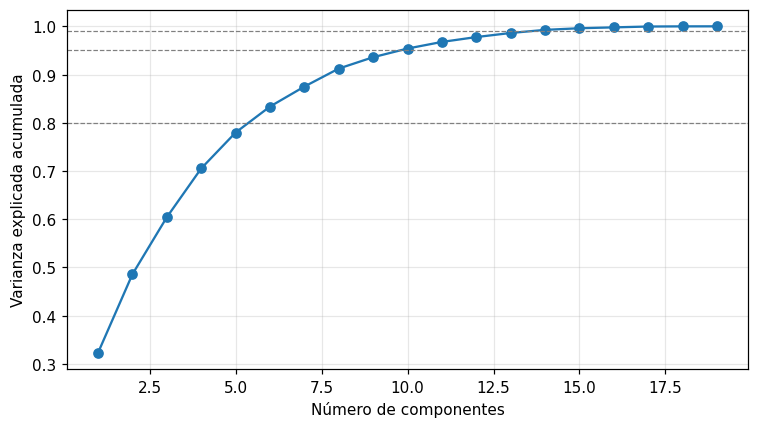

In [ ]:
esc = escalador()
pca_total = PCA(random_state=RANDOM_STATE).fit(esc.fit_transform(X.iloc[idx_train]))
acumulada = np.cumsum(pca_total.explained_variance_ratio_)
DIMENSIONES_PCA = sorted({int(np.searchsorted(acumulada, u) + 1) for u in UMBRALES_PCA})
print('Componentes para 80 %, 95 % y 99 % de la varianza:', DIMENSIONES_PCA)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(acumulada) + 1), acumulada, marker='o')
for u in UMBRALES_PCA:
    plt.axhline(u, color='gray', ls='--', lw=.8)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURAS / 'pca_varianza.png', dpi=200)
plt.show()

In [ ]:
RESUMEN_PCA = []
for nombre in MODELOS:
    for n in DIMENSIONES_PCA:
        s = buscar_espacio('PCA', n, nombre)
        RESUMEN_PCA.append(s)
        print(f"PCA {n}, {nombre}: MCC val {s['val'][0]:.4f} +/- {2 * s['val'][1]:.4f} ({s['minutos']:.1f} min)", flush=True)

tabla_pca = tabla_espacio(RESUMEN_PCA)
tabla_pca.to_csv(RESULTADOS / 'tabla_pca.csv')
print(tabla_pca.to_string())

PCA 6, MLP: MCC val 0.9718 +/- 0.0025 (24.8 min)
PCA 10, MLP: MCC val 0.9916 +/- 0.0027 (19.5 min)
PCA 14, MLP: MCC val 0.9957 +/- 0.0012 (11.2 min)
PCA 6, SVM: MCC val 0.9483 +/- 0.0100 (42.9 min)
PCA 10, SVM: MCC val 0.9760 +/- 0.0084 (44.5 min)
PCA 14, SVM: MCC val 0.9932 +/- 0.0016 (42.0 min)
                    Reducción %          MCC val         MCC test  FPR test                                         Hiperparámetros
Modelo Dimensiones                                                                                                                 
MLP    19                   0.0  0.9956 ± 0.0014           0.9960    0.0001                                           Sin reducción
       6                   68.4  0.9718 ± 0.0025  0.9738 ± 0.0021    0.0089  {'alpha': 0.0001, 'hidden_layer_sizes': [128, 64, 32]}
       10                  47.4  0.9916 ± 0.0027  0.9901 ± 0.0013    0.0026       {'alpha': 0.0001, 'hidden_layer_sizes': [64, 32]}
       14                  26.3  0.9957 ± 

## 5.5 UMAP

UMAP no ofrece una medida equivalente a la varianza explicada, así que el número de componentes se justifica
empíricamente: se comparan 2, 5 y 10 dimensiones, siendo 10 la dimensión que retiene el 95 % de varianza en PCA. Se
usan `n_neighbors=15` y `min_dist=0.1`, los valores por defecto de la librería.

In [ ]:
RESUMEN_UMAP = []
for nombre in MODELOS:
    for n in DIMENSIONES_UMAP:
        s = buscar_espacio('UMAP', n, nombre)
        RESUMEN_UMAP.append(s)
        print(f"UMAP {n}, {nombre}: MCC val {s['val'][0]:.4f} +/- {2 * s['val'][1]:.4f} ({s['minutos']:.1f} min)", flush=True)

tabla_umap = tabla_espacio(RESUMEN_UMAP)
tabla_umap.to_csv(RESULTADOS / 'tabla_umap.csv')
print(tabla_umap.to_string())

UMAP 2, MLP: MCC val 0.7755 +/- 0.0278 (52.3 min)
UMAP 5, MLP: MCC val 0.8110 +/- 0.0152 (23.2 min)
UMAP 10, MLP: MCC val 0.8196 +/- 0.0075 (21.5 min)


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


UMAP 2, SVM: MCC val 0.6816 +/- 0.0730 (67.1 min)
UMAP 5, SVM: MCC val 0.8226 +/- 0.0157 (44.4 min)
UMAP 10, SVM: MCC val 0.8312 +/- 0.0166 (44.1 min)
                    Reducción %          MCC val         MCC test  FPR test                                         Hiperparámetros
Modelo Dimensiones                                                                                                                 
MLP    19                   0.0  0.9956 ± 0.0014           0.9960    0.0001                                           Sin reducción
       2                   89.5  0.7755 ± 0.0278  0.7890 ± 0.0055    0.0332  {'alpha': 0.0001, 'hidden_layer_sizes': [128, 64, 32]}
       5                   73.7  0.8110 ± 0.0152  0.8290 ± 0.0050    0.0265  {'alpha': 0.0001, 'hidden_layer_sizes': [128, 64, 32]}
       10                  47.4  0.8196 ± 0.0075  0.8313 ± 0.0050    0.0270  {'alpha': 0.0001, 'hidden_layer_sizes': [128, 64, 32]}
SVM    19                   0.0  0.9949 ± 0.0041         

### Proyección de UMAP en dos dimensiones
Cada punto es una URL del conjunto de prueba, proyectada con lo aprendido en entrenamiento.

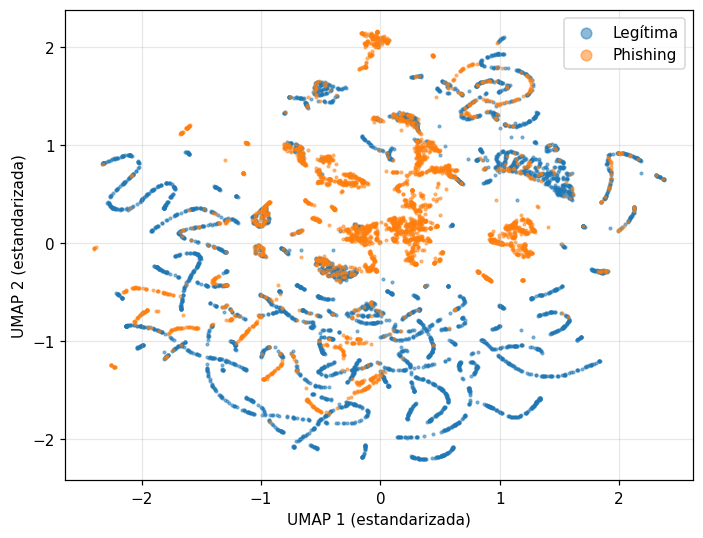

In [ ]:
_, Z_p = proyectar('UMAP', 2, 'completo_final', idx_train, idx_test)
y_p = y[idx_test]
muestra = np.random.default_rng(RANDOM_STATE).choice(len(Z_p), min(8_000, len(Z_p)), replace=False)
plt.figure(figsize=(6.5, 5))
for clase, etiqueta in [(0, 'Legítima'), (1, 'Phishing')]:
    m = muestra[y_p[muestra] == clase]
    plt.scatter(Z_p[m, 0], Z_p[m, 1], s=3, alpha=.5, label=etiqueta)
plt.xlabel('UMAP 1 (estandarizada)')
plt.ylabel('UMAP 2 (estandarizada)')
plt.legend(markerscale=4)
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURAS / 'umap_2d.png', dpi=200)
plt.show()

## 5.6 Comparación
La línea punteada es el MCC de validación con las 19 variables.

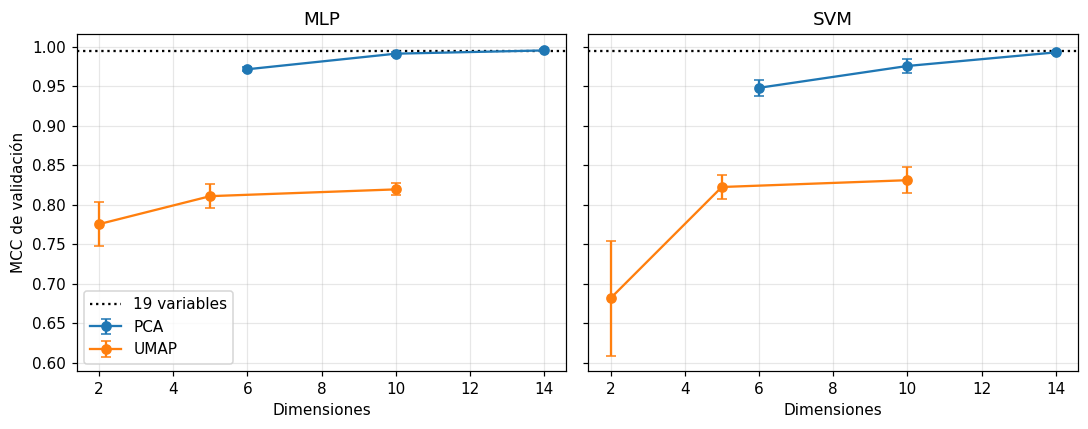

In [ ]:
fig, ejes = plt.subplots(1, len(MODELOS), figsize=(10, 4), sharey=True)
for eje, nombre in zip(ejes, MODELOS):
    r = BASE[nombre][0]
    eje.axhline(r['validacion']['mcc'], color='k', ls=':', label='19 variables')
    for etiqueta, resumenes in [('PCA', RESUMEN_PCA), ('UMAP', RESUMEN_UMAP)]:
        partes = sorted([s for s in resumenes if s['modelo'] == nombre], key=lambda s: s['n'])
        eje.errorbar([s['n'] for s in partes], [s['val'][0] for s in partes], yerr=[2 * s['val'][1] for s in partes],
                     marker='o', capsize=3, label=etiqueta)
    eje.set_title(nombre)
    eje.set_xlabel('Dimensiones')
    eje.grid(alpha=.3)
ejes[0].set_ylabel('MCC de validación')
ejes[0].legend()
plt.tight_layout()
plt.savefig(FIGURAS / 'reduccion_comparacion.png', dpi=200)
plt.show()